In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns

df = pd.read_csv(
    "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


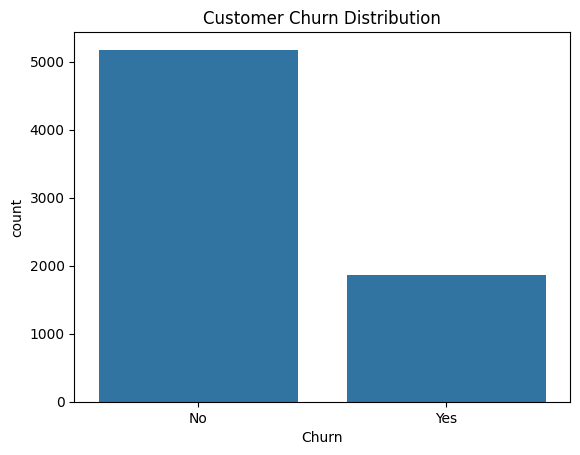

In [5]:
print(df["Churn"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


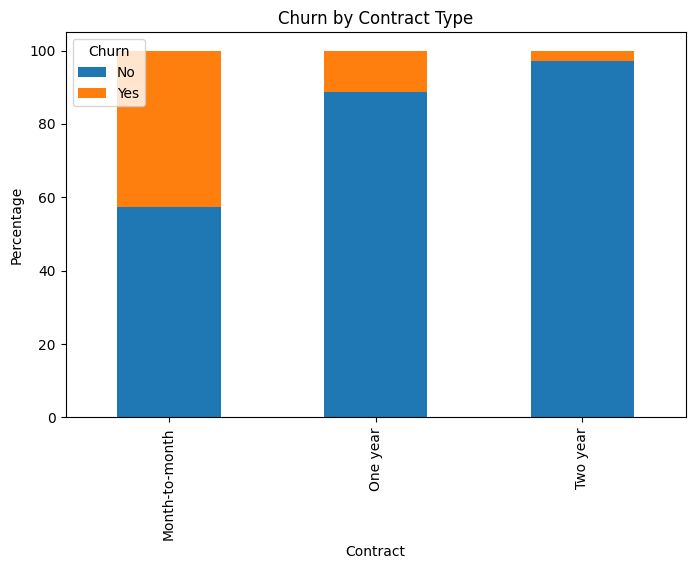

In [6]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract)

churn_by_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)
plt.title("Churn by Contract Type")
plt.ylabel("Percentage")
plt.show()

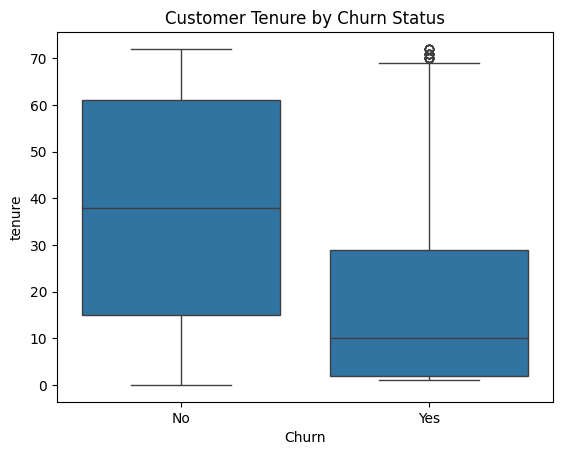

In [7]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure by Churn Status")
plt.show()

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

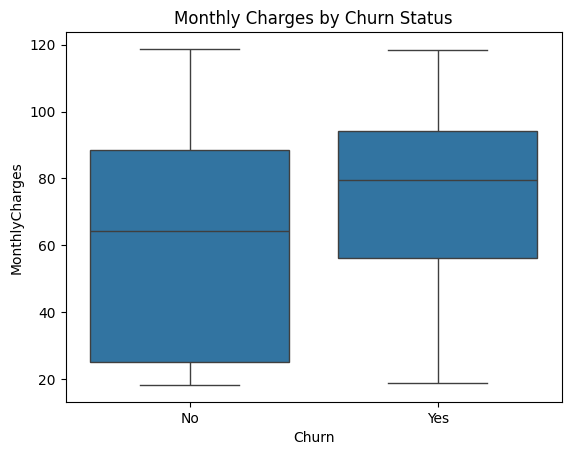

In [9]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.show()

In [73]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Calculate counts directly from your dataset
gender_counts = df["gender"].value_counts()
churn_counts = df["Churn"].value_counts()

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "domain"}, {"type": "domain"}]],
    subplot_titles=["Gender distribution", "Churn distribution"]
)

fig.add_trace(
    go.Pie(
        labels=gender_counts.index,
        values=gender_counts.values,
        name="Gender",
        marker_colors=["#6366F1", "#A5B4FC"]
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Pie(
        labels=churn_counts.index,
        values=churn_counts.values,
        name="Churn",
        marker_colors=[
            "#EF4444" if label == "Yes" else "#3B82F6"
            for label in churn_counts.index
        ]
    ),
    row=1,
    col=2
)

fig.update_traces(
    hole=0.45,
    textinfo="label+percent",
    textfont_size=15,
    hovertemplate="%{label}: %{value} customers (%{percent})<extra></extra>"
)

fig.update_layout(
    title_text="Telco Customers — Gender and Churn",
    template="plotly_white",
    height=450,
    showlegend=False
)

fig.show(renderer="iframe")

In [69]:
df["Churn"][df["Churn"]=="No"].groupby(by=df["gender"]).count()

gender
Female    2549
Male      2625
Name: Churn, dtype: int64

In [70]:
df["Churn"][df["Churn"]=="Yes"].groupby(by=df["gender"]).count()


gender
Female    939
Male      930
Name: Churn, dtype: int64

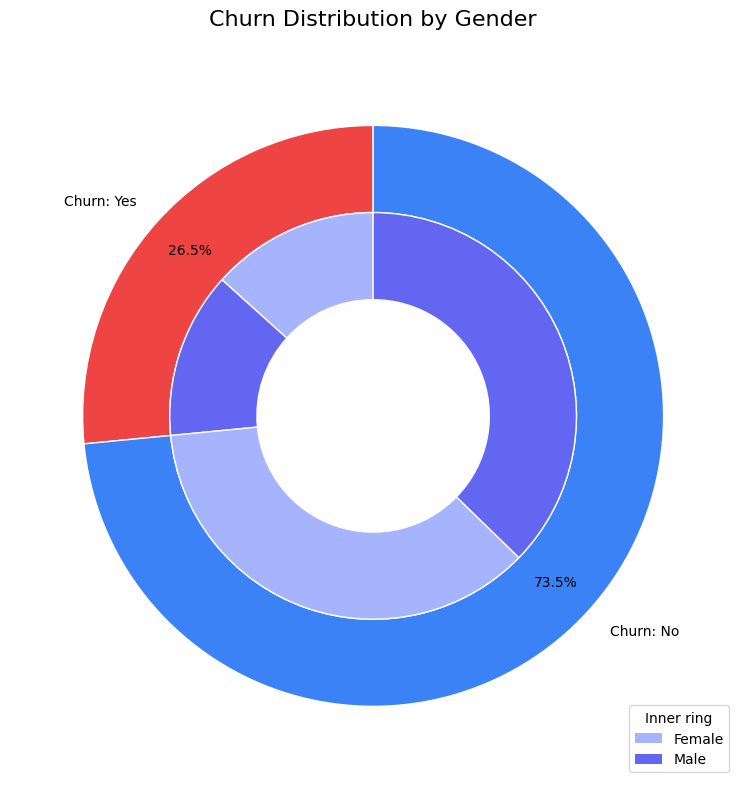

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Rows are churn outcomes; columns are genders
counts = pd.crosstab(df["Churn"], df["gender"]).reindex(
    index=["Yes", "No"],
    columns=["Female", "Male"],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 8))

# Outer ring shows churn totals
ax.pie(
    counts.sum(axis=1).to_numpy(),
    radius=1,
    labels=["Churn: Yes", "Churn: No"],
    colors=["#EF4444", "#3B82F6"],
    startangle=90,
    autopct="%1.1f%%",
    pctdistance=0.85,
    wedgeprops={"width": 0.3, "edgecolor": "white"}
)

# Inner ring splits each churn outcome by gender
ax.pie(
    counts.to_numpy().flatten(),
    radius=0.7,
    colors=["#A5B4FC", "#6366F1"] * 2,
    startangle=90,
    wedgeprops={"width": 0.3, "edgecolor": "white"}
)

ax.legend(
    handles=[
        Patch(facecolor="#A5B4FC", label="Female"),
        Patch(facecolor="#6366F1", label="Male")
    ],
    title="Inner ring",
    loc="lower right"
)

ax.set_title("Churn Distribution by Gender", fontsize=16, pad=20)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [10]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [12]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [14]:
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

float64
11


In [15]:
(df.loc[df["tenure"] == 0, "TotalCharges"] == 0).all()

np.False_

In [16]:
df.loc[df["tenure"] == 0, ["tenure", "TotalCharges"]]


,tenure,TotalCharges
488,0,NaN
753,0,NaN
936,0,NaN
1082,0,NaN
1340,0,NaN
3331,0,NaN
3826,0,NaN
4380,0,NaN
5218,0,NaN
6670,0,NaN


In [17]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

float64
0


In [18]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


# *Starting with LOGISTIC REGRESSION Model*


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Training churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)
Training churn distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing churn distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [20]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [22]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


**Starting the predictions**


In [23]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

First 10 actual values:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']


In [24]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.8055358410220014

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



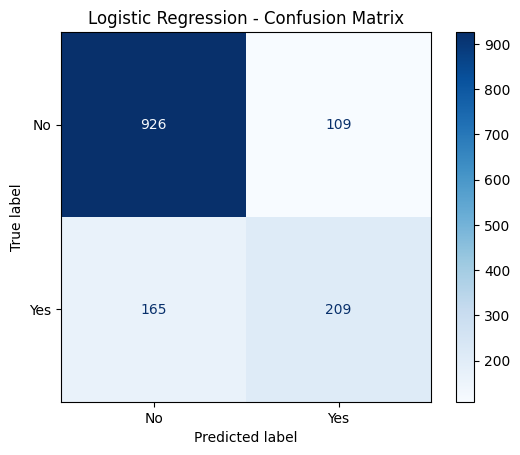

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

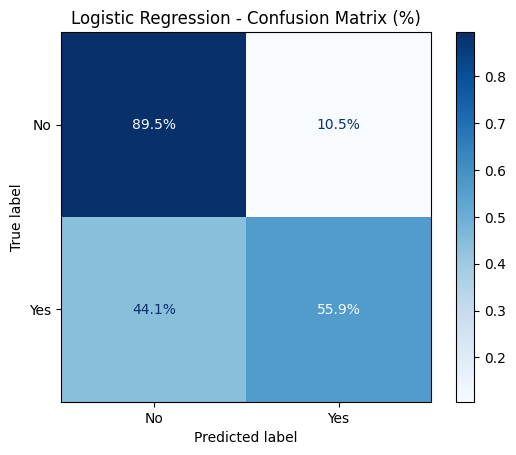

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["No", "Yes"],
    normalize="true",
    values_format=".1%",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix (%)")
plt.show()


In [27]:
import numpy as np

# Probability that each customer will churn
churn_index = list(model.classes_).index("Yes")
y_prob = model.predict_proba(X_test)[:, churn_index]

print("First 10 churn probabilities:")
print(np.round(y_prob[:10], 3))

First 10 churn probabilities:
[0.046 0.684 0.059 0.402 0.021 0.603 0.448 0.13  0.003 0.395]


In [28]:
# Get predicted probabilities of churn
churn_index = list(model.classes_).index("Yes")
y_prob = model.predict_proba(X_test)[:, churn_index]

# Change the threshold
threshold = 0.35

y_pred_new = [
    "Yes" if prob >= threshold else "No"
    for prob in y_prob
]

print(classification_report(y_test, y_pred_new))

              precision    recall  f1-score   support

          No       0.88      0.79      0.83      1035
         Yes       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



# *Let's try RANDOM FOREST Model*


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

          No       0.82      0.89      0.86      1035
         Yes       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (0.50)",
        "Logistic Regression (0.35)",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_new),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision (Yes)": [
        precision_score(y_test, y_pred, pos_label="Yes"),
        precision_score(y_test, y_pred_new, pos_label="Yes"),
        precision_score(y_test, rf_pred, pos_label="Yes")
    ],
    "Recall (Yes)": [
        recall_score(y_test, y_pred, pos_label="Yes"),
        recall_score(y_test, y_pred_new, pos_label="Yes"),
        recall_score(y_test, rf_pred, pos_label="Yes")
    ],
    "F1 (Yes)": [
        f1_score(y_test, y_pred, pos_label="Yes"),
        f1_score(y_test, y_pred_new, pos_label="Yes"),
        f1_score(y_test, rf_pred, pos_label="Yes")
    ]
})

display(comparison.round(3))

,Model,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
0,Logistic Regression (0.50),0.806,0.657,0.559,0.604
1,Logistic Regression (0.35),0.764,0.543,0.706,0.614
2,Random Forest,0.783,0.619,0.473,0.536


# **After comparing the models, I chose LOGISTIC REGRESSION, now to understand how it operated**

In [31]:
import pandas as pd
import numpy as np

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = model.named_steps[
    "classifier"
].coef_[0]

# Create a table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

display(feature_importance.head(10))
display(feature_importance.tail(10))

,Feature,Coefficient
16,cat__InternetService_Fiber optic,0.634195
36,cat__Contract_Month-to-month,0.582883
3,num__TotalCharges,0.536253
35,cat__StreamingMovies_Yes,0.200938
32,cat__StreamingTV_Yes,0.200481
43,cat__PaymentMethod_Electronic check,0.197867
18,cat__OnlineSecurity_No,0.156279
27,cat__TechSupport_No,0.131503
14,cat__MultipleLines_Yes,0.104649
0,num__SeniorCitizen,0.053449


,Feature,Coefficient
19,cat__OnlineSecurity_No internet service,-0.300104
17,cat__InternetService_No,-0.300104
31,cat__StreamingTV_No internet service,-0.300104
25,cat__DeviceProtection_No internet service,-0.300104
22,cat__OnlineBackup_No internet service,-0.300104
39,cat__PaperlessBilling_No,-0.343227
2,num__MonthlyCharges,-0.591863
15,cat__InternetService_DSL,-0.648646
38,cat__Contract_Two year,-0.776594
1,num__tenure,-1.257539


In [32]:
# Use the predictions from threshold 0.35
results = X_test.copy()

results["Actual_Churn"] = y_test
results["Predicted_Churn"] = y_pred_new
results["Churn_Probability"] = y_prob

# Customers who actually left but were predicted to stay
missed_churners = results[
    (results["Actual_Churn"] == "Yes") &
    (results["Predicted_Churn"] == "No")
]

print("Number of missed churners:", len(missed_churners))

display(missed_churners.head(10))

Number of missed churners: 110


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability
2488,Male,0,No,No,31,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,55.25,1715.65,Yes,No,0.184571
5086,Male,0,No,No,45,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,One year,Yes,Electronic check,20.40,930.45,Yes,No,0.029487
3408,Female,0,No,No,4,Yes,No,DSL,No,Yes,...,No,No,Month-to-month,No,Credit card (automatic),50.70,151.30,Yes,No,0.259157
7011,Female,0,No,No,4,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,60.40,272.15,Yes,No,0.207053
3158,Male,0,Yes,No,18,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Mailed check,49.55,878.35,Yes,No,0.285479
5968,Female,0,No,No,12,Yes,Yes,DSL,No,No,...,Yes,Yes,One year,No,Mailed check,74.05,872.65,Yes,No,0.209067
1577,Female,0,Yes,Yes,17,Yes,No,Fiber optic,No,No,...,Yes,Yes,One year,No,Bank transfer (automatic),98.60,1704.95,Yes,No,0.232930
2361,Female,0,No,Yes,1,Yes,No,DSL,No,No,...,No,No,Month-to-month,No,Mailed check,45.95,45.95,Yes,No,0.295851
1014,Male,0,Yes,Yes,18,Yes,No,DSL,No,No,...,No,Yes,Month-to-month,No,Electronic check,57.45,990.85,Yes,No,0.286137
6388,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.40,20.40,Yes,No,0.189158


In [33]:
# Customers who churned and were correctly identified
correct_churners = results[
    (results["Actual_Churn"] == "Yes") &
    (results["Predicted_Churn"] == "Yes")
]

# Compare numerical characteristics
columns = ["tenure", "MonthlyCharges", "TotalCharges"]

comparison_numeric = pd.DataFrame({
    "Missed churners": missed_churners[columns].mean(),
    "Correctly identified": correct_churners[columns].mean()
})

display(comparison_numeric.round(2))

,Missed churners,Correctly identified
tenure,28.59,11.41
MonthlyCharges,62.93,76.87
TotalCharges,2391.72,987.80


In [34]:
print("Contract types among missed churners:")
print(
    missed_churners["Contract"].value_counts(normalize=True)
    .mul(100).round(1)
)

print("\nContract types among correctly identified churners:")
print(
    correct_churners["Contract"].value_counts(normalize=True)
    .mul(100).round(1)
)

Contract types among missed churners:
Contract
Month-to-month    62.7
One year          29.1
Two year           8.2
Name: proportion, dtype: float64

Contract types among correctly identified churners:
Contract
Month-to-month    98.5
One year           1.5
Name: proportion, dtype: float64


In [35]:
from sklearn.metrics import recall_score

contract_results = []

for contract in results["Contract"].unique():

    group = results[results["Contract"] == contract]

    actual_churners = group[
        group["Actual_Churn"] == "Yes"
    ]

    identified = actual_churners[
        actual_churners["Predicted_Churn"] == "Yes"
    ]

    recall = len(identified) / len(actual_churners)

    contract_results.append({
        "Contract": contract,
        "Actual Churners": len(actual_churners),
        "Correctly Identified": len(identified),
        "Missed": len(actual_churners) - len(identified),
        "Recall (%)": round(recall * 100, 1)
    })

contract_df = pd.DataFrame(contract_results)

display(contract_df.sort_values("Recall (%)"))

,Contract,Actual Churners,Correctly Identified,Missed,Recall (%)
0,Two year,9,0,9,0.0
2,One year,36,4,32,11.1
1,Month-to-month,329,260,69,79.0


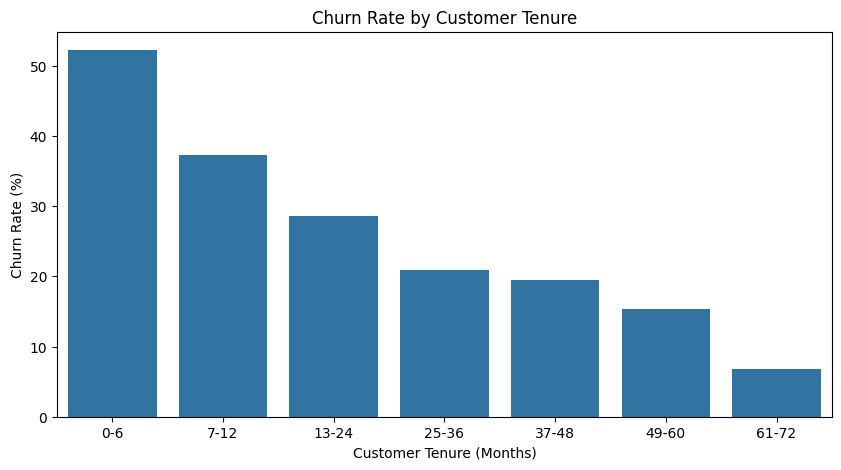

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

tenure_analysis = X_train[["tenure"]].copy()

tenure_analysis["Churn"] = y_train

tenure_analysis["Churn"] = (
    tenure_analysis["Churn"] == "Yes"
).astype(int)

tenure_analysis["TenureGroup"] = pd.cut(
    tenure_analysis["tenure"],
    bins=[-1, 6, 12, 24, 36, 48, 60, 72],
    labels=[
        "0-6", "7-12", "13-24", "25-36",
        "37-48", "49-60", "61-72"
    ]
)

churn_by_tenure = (
    tenure_analysis.groupby(
        "TenureGroup", observed=True
    )["Churn"]
    .mean() * 100
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=churn_by_tenure.index,
    y=churn_by_tenure.values
)

plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Tenure")
plt.show()

**Adding changes to IMPROVE my model** 

In [37]:
def add_features(X):
    X = X.copy()

    X["tenure_squared"] = X["tenure"] ** 2

    X["tenure_x_monthly"] = (
        X["tenure"] * X["MonthlyCharges"]
    )

    X["tenure_x_one_year"] = (
        X["tenure"] * (X["Contract"] == "One year")
    )

    X["tenure_x_two_year"] = (
        X["tenure"] * (X["Contract"] == "Two year")
    )

    return X

In [38]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create transformed training features to identify columns
X_engineered = add_features(X_train)

new_numerical_cols = X_engineered.select_dtypes(
    include=["number"]
).columns.tolist()

new_categorical_cols = X_engineered.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Reuse your existing numerical and categorical transformers
from sklearn.compose import ColumnTransformer

new_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, new_numerical_cols),
        ("cat", categorical_transformer, new_categorical_cols)
    ]
)

improved_model = Pipeline(steps=[
    ("features", FunctionTransformer(add_features)),
    ("preprocessor", new_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("Improved model pipeline created!")

Improved model pipeline created!


In [39]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "recall_yes": "recall_macro",
    "f1_yes": "f1_macro"
}

In [40]:
from sklearn.metrics import make_scorer, recall_score, f1_score

scoring = {
    "accuracy": "accuracy",
    "recall_yes": make_scorer(
        recall_score, pos_label="Yes"
    ),
    "f1_yes": make_scorer(
        f1_score, pos_label="Yes"
    )
}

models = {
    "Original Logistic Regression": model,
    "Engineered Logistic Regression": improved_model
}

cv_results = []

for name, candidate in models.items():

    scores = cross_validate(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Recall (Yes)": scores["test_recall_yes"].mean(),
        "F1 (Yes)": scores["test_f1_yes"].mean()
    })

display(pd.DataFrame(cv_results).round(3))

,Model,Accuracy,Recall (Yes),F1 (Yes)
0,Original Logistic Regression,0.802,0.543,0.592
1,Engineered Logistic Regression,0.809,0.541,0.600


In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created!")

Gradient Boosting pipeline created!


In [42]:
gb_scores = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": gb_scores["test_accuracy"].mean(),
    "Recall (Yes)": gb_scores["test_recall_yes"].mean(),
    "F1 (Yes)": gb_scores["test_f1_yes"].mean()
}

cv_results.append(gb_results)

display(pd.DataFrame(cv_results).round(3))

,Model,Accuracy,Recall (Yes),F1 (Yes)
0,Original Logistic Regression,0.802,0.543,0.592
1,Engineered Logistic Regression,0.809,0.541,0.600
2,Gradient Boosting,0.802,0.525,0.585


# Try to make better changes to reach better RECALL


In [43]:
# Start from the original training and test data
X_train_new = X_train.drop(columns=["TotalCharges"])
X_test_new = X_test.drop(columns=["TotalCharges"])

print("Training shape:", X_train_new.shape)
print("Testing shape:", X_test_new.shape)

Training shape: (5634, 18)
Testing shape: (1409, 18)


In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numerical_cols_new = X_train_new.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols_new = X_train_new.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor_new = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_cols_new),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols_new)
    ]
)

In [45]:
import pandas as pd
import numpy as np

# Remove TotalCharges
X_train_new = X_train.drop(columns=["TotalCharges"]).copy()
X_test_new = X_test.drop(columns=["TotalCharges"]).copy()

# Combine training features and labels temporarily
train_data = X_train_new.copy()
train_data["Churn"] = y_train

print("Original training distribution:")
print(train_data["Churn"].value_counts())

Original training distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64


In [46]:
# Separate customers by churn status
yes_customers = train_data[
    train_data["Churn"] == "Yes"
]

no_customers = train_data[
    train_data["Churn"] == "No"
]

# How many extra Yes customers do we need?
needed = len(no_customers) - len(yes_customers)

print("Additional Yes rows needed:", needed)

# Randomly select churners with replacement
synthetic_yes = yes_customers.sample(
    n=needed,
    replace=True,
    random_state=42
).copy()

# Flip gender
synthetic_yes["gender"] = synthetic_yes["gender"].map({
    "Male": "Female",
    "Female": "Male"
})

print("Synthetic customers created:", len(synthetic_yes))

Additional Yes rows needed: 2644
Synthetic customers created: 2644


In [47]:
balanced_train = pd.concat(
    [train_data, synthetic_yes],
    ignore_index=True
)

# Shuffle rows
balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("New training distribution:")
print(balanced_train["Churn"].value_counts())

print("\nPercentages:")
print(
    balanced_train["Churn"].value_counts(normalize=True) * 100
)

New training distribution:
Churn
No     4139
Yes    4139
Name: count, dtype: int64

Percentages:
Churn
No     50.0
Yes    50.0
Name: proportion, dtype: float64


In [48]:
X_train_balanced = balanced_train.drop(columns=["Churn"])
y_train_balanced = balanced_train["Churn"]

print(X_train_balanced.shape)
print(y_train_balanced.shape)

(8278, 18)
(8278,)


In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

num_cols = X_train_balanced.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = X_train_balanced.select_dtypes(
    include=["object", "category"]
).columns.tolist()

new_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

new_model = Pipeline([
    ("preprocessor", new_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

new_model.fit(X_train_balanced, y_train_balanced)

print("New model trained successfully!")

New model trained successfully!


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using the new model
y_pred_balanced = new_model.predict(X_test_new)

# Calculate performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 3))
print("Precision (Yes):", round(precision_score(y_test, y_pred_balanced, pos_label="Yes"), 3))
print("Recall (Yes):", round(recall_score(y_test, y_pred_balanced, pos_label="Yes"), 3))
print("F1 (Yes):", round(f1_score(y_test, y_pred_balanced, pos_label="Yes"), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Accuracy: 0.74
Precision (Yes): 0.507
Recall (Yes): 0.775
F1 (Yes): 0.613

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.73      0.80      1035
         Yes       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



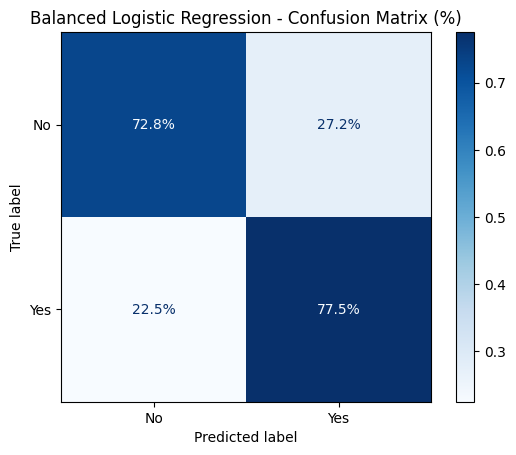

In [51]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    labels=["No", "Yes"],
    normalize="true",
    values_format=".1%",
    cmap="Blues"
)

plt.title("Balanced Logistic Regression - Confusion Matrix (%)")
plt.show()

In [52]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression (0.50)",
        "Original Logistic Regression (0.35)",
        "New Balanced Logistic Regression"
    ],
    "Accuracy": [
        0.806,
        0.764,
        accuracy_score(y_test, y_pred_balanced)
    ],
    "Precision (Yes)": [
        0.657,
        0.543,
        precision_score(y_test, y_pred_balanced, pos_label="Yes")
    ],
    "Recall (Yes)": [
        0.559,
        0.706,
        recall_score(y_test, y_pred_balanced, pos_label="Yes")
    ],
    "F1 (Yes)": [
        0.604,
        0.614,
        f1_score(y_test, y_pred_balanced, pos_label="Yes")
    ]
})

display(comparison.round(3))

,Model,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
0,Original Logistic Regression (0.50),0.806,0.657,0.559,0.604
1,Original Logistic Regression (0.35),0.764,0.543,0.706,0.614
2,New Balanced Logistic Regression,0.740,0.507,0.775,0.613


In [53]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score
import pandas as pd

# Model without TotalCharges and without oversampling
no_total_model = Pipeline([
    ("preprocessor", new_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Compare using the original training data only
models_to_compare = {
    "No TotalCharges": no_total_model,
    "Balanced + No TotalCharges": new_model
}

In [54]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score

cv_new = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_new = {
    "accuracy": "accuracy",
    "recall_yes": make_scorer(recall_score, pos_label="Yes"),
    "f1_yes": make_scorer(f1_score, pos_label="Yes")
}

In [55]:
scores = cross_validate(
    no_total_model,
    X_train_new,
    y_train,
    cv=cv_new,
    scoring=scoring_new
)

print("Accuracy:", round(scores["test_accuracy"].mean(), 3))
print("Recall (Yes):", round(scores["test_recall_yes"].mean(), 3))
print("F1 (Yes):", round(scores["test_f1_yes"].mean(), 3))

Accuracy: 0.801
Recall (Yes): 0.538
F1 (Yes): 0.589


In [56]:
import pandas as pd

# Numerical columns we want to investigate
columns = ["tenure", "MonthlyCharges"]

for col in columns:

    Q1 = X_train_new[col].quantile(0.25)
    Q3 = X_train_new[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify values outside the boundaries
    outliers = X_train_new[
        (X_train_new[col] < lower_bound) |
        (X_train_new[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers: {len(outliers)}")


Column: tenure
Q1: 9.00
Q3: 55.00
IQR: 46.00
Lower bound: -60.00
Upper bound: 124.00
Number of outliers: 0

Column: MonthlyCharges
Q1: 35.66
Q3: 90.00
IQR: 54.34
Lower bound: -45.84
Upper bound: 171.51
Number of outliers: 0


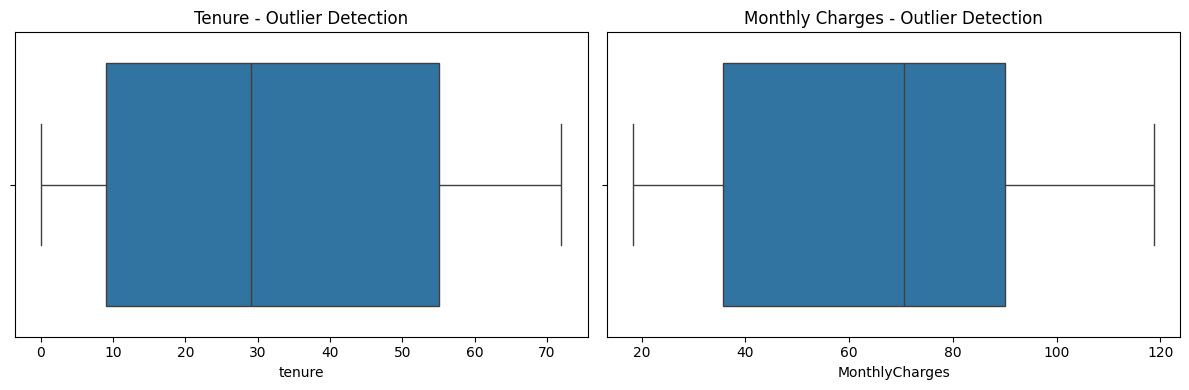

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    x=X_train_new["tenure"],
    ax=axes[0]
)
axes[0].set_title("Tenure - Outlier Detection")

sns.boxplot(
    x=X_train_new["MonthlyCharges"],
    ax=axes[1]
)
axes[1].set_title("Monthly Charges - Outlier Detection")

plt.tight_layout()
plt.show()

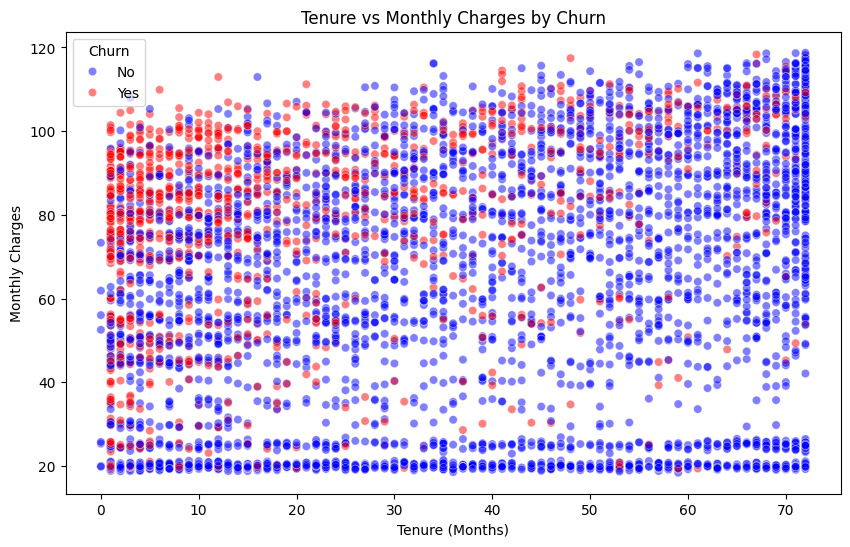

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use original training data, without synthetic customers
plot_data = X_train_new.copy()
plot_data["Churn"] = y_train

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_data,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    palette={"Yes": "red", "No": "blue"},
    alpha=0.5
)

plt.title("Tenure vs Monthly Charges by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Churn")
plt.show()

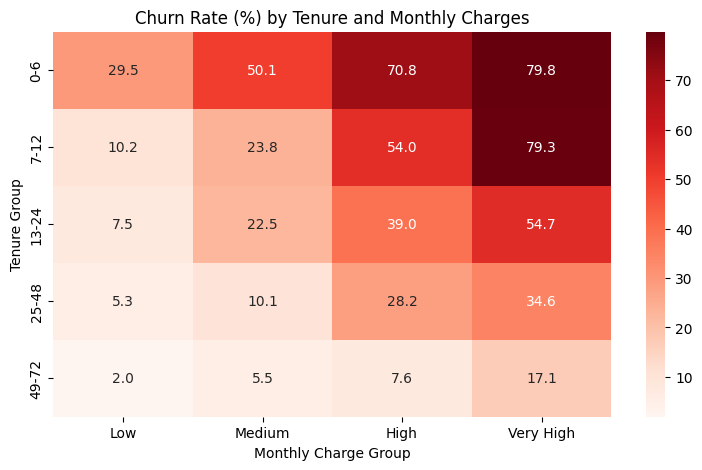

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Original training data only
analysis_df = X_train_new.copy()
analysis_df["Churn"] = y_train

# Create tenure categories
analysis_df["TenureGroup"] = pd.cut(
    analysis_df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

# Create monthly charge categories
analysis_df["ChargeGroup"] = pd.cut(
    analysis_df["MonthlyCharges"],
    bins=[0, 40, 70, 90, 120],
    labels=["Low", "Medium", "High", "Very High"]
)

# Calculate churn rate in each segment
analysis_df["ChurnBinary"] = (
    analysis_df["Churn"] == "Yes"
).astype(int)

churn_heatmap = analysis_df.pivot_table(
    index="TenureGroup",
    columns="ChargeGroup",
    values="ChurnBinary",
    aggfunc="mean",
    observed=True
) * 100

plt.figure(figsize=(9, 5))

sns.heatmap(
    churn_heatmap,
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

plt.title("Churn Rate (%) by Tenure and Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Tenure Group")
plt.show()

In [60]:
def add_segment_feature(X):
    X = X.copy()

    tenure_group = pd.cut(
        X["tenure"],
        bins=[-1, 6, 12, 24, 48, 72],
        labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
    )

    charge_group = pd.cut(
        X["MonthlyCharges"],
        bins=[0, 40, 70, 90, 120],
        labels=["Low", "Medium", "High", "Very High"]
    )

    X["TenureChargeSegment"] = (
        tenure_group.astype(str)
        + "_"
        + charge_group.astype(str)
    )

    return X

# *Lastest model version: Keeping LOGISTIC REGRESSION. Trying a better oversampling method plus adding PCA, plus changing the threshold to 0.35* 

In [61]:
# Original training data, not gender-switched data
X_original = X_train.drop(columns=["TotalCharges"]).copy()
y_original = y_train.copy()

print("Original churn distribution:")
print(y_original.value_counts())

Original churn distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64


In [62]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_cols = X_original.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = X_original.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor_pca = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), cat_cols)
])

In [63]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

pca_balanced_model = ImbPipeline([
    ("preprocessor", preprocessor_pca),
    ("oversampler", RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(
        max_iter=2000
    ))
])

print("PCA + Oversampling model created!")

PCA + Oversampling model created!


In [64]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score

cv_pca = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_pca = {
    "accuracy": "accuracy",
    "recall_yes": make_scorer(
        recall_score, pos_label="Yes"
    ),
    "f1_yes": make_scorer(
        f1_score, pos_label="Yes"
    )
}

pca_scores = cross_validate(
    pca_balanced_model,
    X_original,
    y_original,
    cv=cv_pca,
    scoring=scoring_pca
)

print("Accuracy:", round(pca_scores["test_accuracy"].mean(), 3))
print("Recall (Yes):", round(pca_scores["test_recall_yes"].mean(), 3))
print("F1 (Yes):", round(pca_scores["test_f1_yes"].mean(), 3))

Accuracy: 0.757
Recall (Yes): 0.782
F1 (Yes): 0.63


In [65]:
from sklearn.base import clone

oversampling_only_model = ImbPipeline([
    ("preprocessor", clone(preprocessor_pca)),
    ("oversampler", RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("classifier", LogisticRegression(max_iter=2000))
])

no_pca_scores = cross_validate(
    oversampling_only_model,
    X_original,
    y_original,
    cv=cv_pca,
    scoring=scoring_pca
)

comparison_pca = pd.DataFrame([
    {
        "Model": "Oversampling only",
        "Accuracy": no_pca_scores["test_accuracy"].mean(),
        "Recall (Yes)": no_pca_scores["test_recall_yes"].mean(),
        "F1 (Yes)": no_pca_scores["test_f1_yes"].mean()
    },
    {
        "Model": "Oversampling + PCA",
        "Accuracy": pca_scores["test_accuracy"].mean(),
        "Recall (Yes)": pca_scores["test_recall_yes"].mean(),
        "F1 (Yes)": pca_scores["test_f1_yes"].mean()
    }
])

display(comparison_pca.round(3))

,Model,Accuracy,Recall (Yes),F1 (Yes)
0,Oversampling only,0.749,0.791,0.625
1,Oversampling + PCA,0.757,0.782,0.630


In [66]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

threshold = 0.35
fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_original, y_original), start=1
):
    # Separate training and validation customers for this fold
    X_fold_train = X_original.iloc[train_idx]
    X_fold_val = X_original.iloc[val_idx]
    y_fold_train = y_original.iloc[train_idx]
    y_fold_val = y_original.iloc[val_idx]

    # Fit a fresh pipeline using only this fold's training data
    fold_model = clone(oversampling_only_model)
    fold_model.fit(X_fold_train, y_fold_train)

    # Apply the 35% threshold to validation predictions
    yes_col = list(fold_model.classes_).index("Yes")
    scores = fold_model.predict_proba(X_fold_val)[:, yes_col]
    predictions = np.where(scores > threshold, "Yes", "No")

    fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_fold_val, predictions),
        "Precision (Yes)": precision_score(
            y_fold_val, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall (Yes)": recall_score(
            y_fold_val, predictions, pos_label="Yes", zero_division=0
        ),
        "F1 (Yes)": f1_score(
            y_fold_val, predictions, pos_label="Yes", zero_division=0
        )
    })

results = pd.DataFrame(fold_results).set_index("Fold")

print("Performance in each fold:")
display(results.round(3))

print("Average and standard deviation across folds:")
display(results.agg(["mean", "std"]).round(3))

Performance in each fold:


,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
Fold,,,,
1,0.681,0.450,0.900,0.600
2,0.676,0.444,0.876,0.589
3,0.673,0.441,0.860,0.583
4,0.665,0.438,0.926,0.594
5,0.699,0.466,0.910,0.616


Average and standard deviation across folds:


,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
mean,0.679,0.448,0.894,0.596
std,0.013,0.011,0.027,0.013


In [67]:
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix

# Train your oversampling-only model
model = clone(oversampling_only_model)
model.fit(X_original, y_original)

# Get each test customer's score for "Yes"
X_test_model = X_test.loc[:, X_original.columns]
yes_col = list(model.classes_).index("Yes")
test_scores = model.predict_proba(X_test_model)[:, yes_col]

# Predict churn when the score is above 35%
test_pred = np.where(test_scores > threshold, "Yes", "No")

# Evaluate predictions
print(classification_report(
    y_test, test_pred, labels=["No", "Yes"], digits=3
))

cm = confusion_matrix(y_test, test_pred, labels=["No", "Yes"])
display(pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

              precision    recall  f1-score   support

          No      0.943     0.602     0.735      1035
         Yes      0.449     0.898     0.599       374

    accuracy                          0.681      1409
   macro avg      0.696     0.750     0.667      1409
weighted avg      0.812     0.681     0.699      1409



,Predicted No,Predicted Yes
Actual No,623,412
Actual Yes,38,336
